# A microstructure as the sample

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/igbaskin/cmf-qsar/blob/main/docs/tutorials/26_a_microstructure.ipynb)

A two-phase microstructure on a grid of voxels has no atoms, but it is a field: the indicator
of each phase, one value per voxel. The kernel of this program, the overlap of two fields,
applies to it as it stands. Because the cells of a set share a grid but not a frame, the useful
form is the overlap of their **two-point statistics**: the probability that two voxels a vector
r apart are both in phase 1. That statistic is the autocorrelation of the phase field, and it is
also the descriptor of the Materials Knowledge Systems (MKS), the established approach to
microstructure informatics.

The data are synthetic: 400 cells of 51 × 51 voxels, made by cutting smoothed random noise at a
quantile. Four numbers vary from cell to cell: the phase fraction, the grain size, the elongation
of the grains and their direction. The label is the effective thermal conductivity of the cell,
from a finite-volume solver: the component along x, which depends on the direction of the grains,
and the mean over the directions, which does not. Phase 1 conducts 10 or 100 times better than
phase 0.

The notebook asks four questions.

1. Does the autocorrelation kernel predict the conductivity better than the phase fraction?
2. The reference: does it predict better than a few numbers measured on each cell, the phase
   fraction and the correlation length of phase 1 along each axis?
3. For a property that depends on two scales, does the product of two kernels beat those numbers
   with the second-scale descriptor added?
4. What can the kernel show that a few numbers cannot?

The cells are built and solved live, in about 5 seconds per set. The Gaussian-process baseline,
the 3D cells, the elastic label and the real micrographs are read from the stored runs of
`benchmarks/run_microstructure.py`. Running time: about one minute.

In [1]:
# Run this cell first. On Google Colab it fetches the repository and installs the package;
# on a local checkout it only moves to the repository root, so that the example paths work.
import os, subprocess, sys

if "google.colab" in sys.modules:
    if not os.path.exists("cmf-qsar"):
        subprocess.run(["git", "clone", "-q", "https://github.com/igbaskin/cmf-qsar.git"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "./cmf-qsar", "py3Dmol"], check=True)
    os.chdir("cmf-qsar")
else:
    while not os.path.exists("pyproject.toml") and os.path.dirname(os.getcwd()) != os.getcwd():
        os.chdir("..")
print("working in", os.getcwd())

working in C:\Users\baski\work\claude\cmf


## The cells, their two-point statistics and the numbers

The cell builds the 400 cells at a contrast of 10 and solves each one. It draws three of them,
with the two-point statistics of phase 1 below each, and prints the numbers of the reference:
the phase fraction, and the correlation length of phase 1 along x and along y. A correlation
length is the lag at which the normalised two-point statistic falls below 1/e.

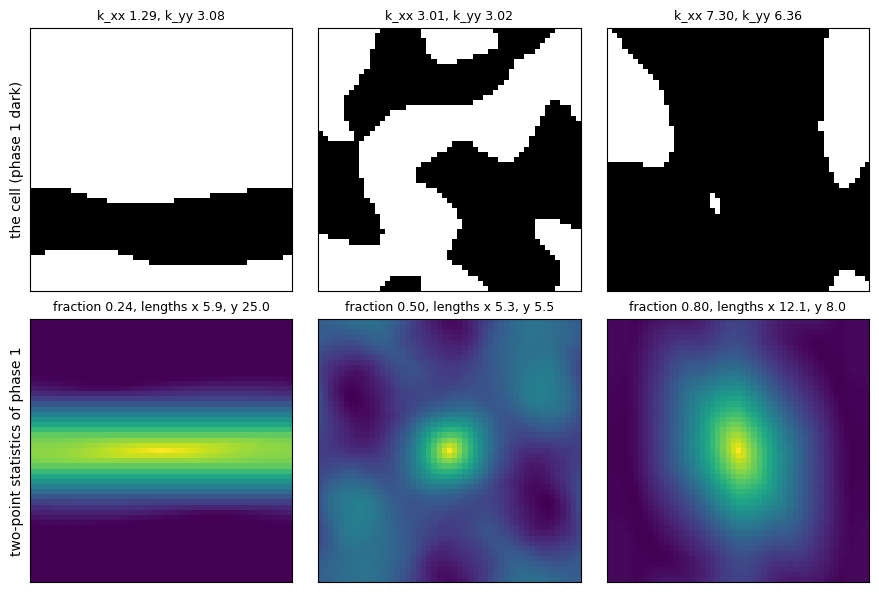

cells ready in 0 s (about 5 s to build and solve on the first run); k_xx from 1.29 to 7.30


In [2]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, "benchmarks")
import run_microstructure as RM                  # the benchmark script of the microstructure pilot

start = time.time()
cells = RM.build_data(2, 51, 400, 10.0)          # 400 cells, contrast 10; solved here on the first run
y = RM.labels(cells)
numbers = RM.shape_numbers(cells["phase"])       # fraction, log length along x, log length along y
lengths = np.exp(numbers[:, 1:])
stats = RM.autocorrelations(RM.smoothed_fields(cells["phase"], 0.0))[:, 0]   # S_11(r) of every cell

show = [int(np.argmin(y["xx"])), int(np.argmin(np.abs(y["xx"] - np.median(y["xx"])))), int(np.argmax(y["xx"]))]
fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for col, i in enumerate(show):
    axes[0, col].imshow(cells["phase"][i], cmap="gray_r")
    axes[0, col].set_title("k_xx %.2f, k_yy %.2f" % (cells["tensor"][i, 0, 0], cells["tensor"][i, 1, 1]), fontsize=9)
    axes[1, col].imshow(np.fft.fftshift(stats[i]), cmap="viridis")
    axes[1, col].set_title("fraction %.2f, lengths x %.1f, y %.1f" % (numbers[i, 0], lengths[i, 0], lengths[i, 1]), fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel("the cell (phase 1 dark)")
axes[1, 0].set_ylabel("two-point statistics of phase 1")
plt.tight_layout()
plt.show()
print("cells ready in %.0f s (about 5 s to build and solve on the first run); k_xx from %.2f to %.2f"
      % (time.time() - start, y["xx"].min(), y["xx"].max()))

The three cells are the one with the lowest conductivity along x, a cell near the median, and the
one with the highest. Phase 1 conducts ten times better, so k_xx grows with the fraction of phase
1 and with how well its grains connect along x. Grains elongated along x make a streak along x
in the two-point statistics, and a long correlation length along x.

Before any model, a note on the reference. The cells were made from four numbers: the fraction,
the grain size, the elongation and the direction. The fraction and the two correlation lengths
are close measurements of those numbers. So the reference may have most of what decides the
conductivity of these cells. That is the reason to try it.

## The kernel against the numbers

The cell runs three models on the draws of the benchmark: 20 random training sets of each size,
the rest of the 400 cells held out, every setting chosen by an inner five-fold cross-validation
on the training set.

- **phase fraction**: a cubic polynomial of the fraction alone.
- **autocorrelation kernel**: kernel ridge regression on the overlap of the two-point statistics,
  with the smoothing width, the layer and the ridge chosen inside (40 settings).
- **fraction and correlation lengths**: a polynomial of degree 1 to 3, or a Gaussian kernel, on
  the three numbers, whichever the inner cross-validation prefers (32 settings).

It does this for both contrasts and both labels, and it checks that the kernel repeats the stored
runs of the benchmark exactly.

In [3]:
start = time.time()
with open("benchmarks/results/microstructure/gate_2d51_n400_c10.json", encoding="utf-8") as fh:
    stored_c10 = json.load(fh)["runs"]
live = {}
for contrast in (10.0, 100.0):
    data = RM.build_data(2, 51, 400, contrast)
    ys = RM.labels(data)
    fraction = data["phase"].reshape(400, -1).mean(axis=1)
    Z = RM.shape_numbers(data["phase"])
    kernels = {s: RM.kernels_for(data, s)["autocorrelation, linear"] for s in RM.GATE.smooth}
    for label in ("xx", "mean"):
        y_l = ys[label]
        for size in RM.SIZES:
            q = {"phase fraction": [], "autocorrelation kernel": [], "fraction and correlation lengths": []}
            for rep in range(20):
                perm = np.random.RandomState(1000 * size + rep).permutation(400)
                train, test = perm[:size], perm[size:]
                fits = {"phase fraction": RM.fit_fraction(fraction, y_l, train, test),
                        "autocorrelation kernel": RM.fit_kernel_method(kernels, y_l, train, test, RM.GATE),
                        "fraction and correlation lengths": RM.fit_shape(Z, y_l, train, test)}
                for m, r in fits.items():
                    q[m].append(RM.r2_score(y_l[test], r["pred"]))
            live[(contrast, label, size)] = {m: np.array(v) for m, v in q.items()}

print("q2 on the held-out cells, mean of 20 draws; 'numbers better' counts the draws in which")
print("the fraction and correlation lengths beat the kernel")
print("%-9s %-5s %5s %15s %13s %12s %15s" % ("contrast", "label", "size", "phase fraction", "kernel", "numbers", "numbers better"))
for (contrast, label, size), q in live.items():
    k, s = q["autocorrelation kernel"], q["fraction and correlation lengths"]
    print("%-9g %-5s %5d %15.3f %13.3f %12.3f %12d of 20" % (contrast, label, size, q["phase fraction"].mean(),
          k.mean(), s.mean(), int(np.sum(s > k))))
same = all(np.allclose(live[(10.0, "xx", n)]["autocorrelation kernel"],
                       [r["q2"] for r in stored_c10["xx"][str(n)]["autocorrelation, linear"]]) for n in RM.SIZES)
print()
print("the kernel repeats the stored runs:", same, "(%.0f s)" % (time.time() - start))

q2 on the held-out cells, mean of 20 draws; 'numbers better' counts the draws in which
the fraction and correlation lengths beat the kernel
contrast  label  size  phase fraction        kernel      numbers  numbers better
10        xx       20           0.850         0.895        0.931           13 of 20
10        xx       50           0.879         0.955        0.967           18 of 20
10        xx      100           0.887         0.966        0.972           19 of 20
10        xx      200           0.885         0.975        0.976           13 of 20
10        mean     20           0.978         0.975        0.956            2 of 20
10        mean     50           0.983         0.979        0.980           14 of 20
10        mean    100           0.984         0.982        0.985           18 of 20
10        mean    200           0.984         0.985        0.987           15 of 20
100       xx       20           0.690         0.750        0.755           11 of 20
100       xx       50  

**The kernel beats the phase fraction** wherever the arrangement matters: on k_xx, by 0.05 to 0.09
in q2 at contrast 10 and by 0.06 to 0.13 at contrast 100. On the direction-free mean, the fraction
alone is as good as anything, as in the published homogenisation examples.

**But the three numbers beat the kernel.** On k_xx they are ahead at every size and at both
contrasts, in 11 to 20 of 20 draws. At contrast 100 with 50 or more cells, the gain is 0.02 to
0.04 in q2, and the numbers are better in 17 to 20 draws. The kernel is clearly ahead only on the
mean label with 20 cells, where a flexible fit of three numbers on 20 cells is unsteady.

The live numbers of the kernel repeat the stored runs of the benchmark exactly.

In [4]:
with open("benchmarks/results/microstructure/shape.json", encoding="utf-8") as fh:
    shape = json.load(fh)
print("the numbers minus a method: mean q2 over 20 draws, and the draws in which the numbers are better")
for tag in ("2d51_n400_c10", "2d51_n400_c100", "3d21_n400_c10"):
    print()
    print(tag)
    print("%-7s %5s %9s %24s %24s" % ("label", "size", "numbers", "minus the kernel", "minus the MKS GP"))
    for label, by_size in shape[tag]["labels"].items():
        for size, b in by_size.items():
            a, g = b["against"]["autocorrelation, linear"], b["against"]["two-point statistics + GP"]
            print("%-7s %5s %+9.3f %16.3f (%2d of 20) %16.3f (%2d of 20)" % (label, size, b["q2"], a["q2"], a["wins"],
                                                                         g["q2"], g["wins"]))

the numbers minus a method: mean q2 over 20 draws, and the draws in which the numbers are better

2d51_n400_c10
label    size   numbers         minus the kernel         minus the MKS GP
xx         20    +0.931            0.036 (13 of 20)            0.067 (15 of 20)
xx         50    +0.967            0.012 (18 of 20)            0.036 (19 of 20)
xx        100    +0.972            0.006 (19 of 20)            0.005 (15 of 20)
xx        200    +0.976            0.001 (13 of 20)           -0.001 ( 8 of 20)
mean       20    +0.956           -0.019 ( 2 of 20)           -0.020 ( 5 of 20)
mean       50    +0.980            0.001 (14 of 20)            0.004 (12 of 20)
mean      100    +0.985            0.002 (18 of 20)            0.002 (18 of 20)
mean      200    +0.987            0.001 (15 of 20)            0.003 (19 of 20)
C_xx       20    +0.913            0.003 (11 of 20)            0.040 (14 of 20)
C_xx       50    +0.973            0.018 (19 of 20)            0.034 (20 of 20)
C_xx      100 

The stored runs add the elastic stiffness from PyMKS, the 3D cells and the current MKS baseline, a
Gaussian process on the principal components of the two-point statistics.

- **The elastic label reads like the conductivity.** In 2D the numbers beat the kernel on C_xx by
  up to 0.06, and beat the Gaussian process by up to 0.18.
- **In 3D the kernel keeps a small lead:** 0.003 to 0.020 on k_xx, in 16 to 18 of 20 draws. The
  3D cells are only 21 voxels wide. Of their 1,200 correlation lengths, 177 do not fall below 1/e
  within half the cell, and the reference can only give them the largest value the grid shows,
  10 voxels. So the 3D reference is a weaker measurement than the 2D one. That is likely, but not
  shown, to be the reason for the small gap.
- **The earlier claim, that the kernel is steadier than the Gaussian process below 100 cells,**
  still holds against the Gaussian process. It does not make the kernel the better choice,
  because the three numbers are steadier still on k_xx in 2D.

## Two scales

In the benchmark's two-scale test, phase 1 of each cell also gets a defect concentration c, and
its conductivity falls with c by a known law. The arrangement and c then decide the property
together. The stored test found that the product of an arrangement kernel and a kernel on c
reaches q2 0.97, against 0.74 for their sum. The reference here is the same three numbers with c
added, given the same choice of a polynomial or a Gaussian kernel.

In [5]:
two = shape["twoscale_2d51_n400_c10"]["labels"]
print("%-6s %5s %9s %28s %34s" % ("label", "size", "numbers", "minus the product kernel", "minus fraction + descriptor"))
for label, by_size in two.items():
    for size, b in by_size.items():
        p, f = b["against"]["product kernel"], b["against"]["phase fraction + descriptor"]
        print("%-6s %5s %+9.3f %20.3f (%2d of 20) %26.3f (%2d of 20)" % (label, size, b["q2"], p["q2"], p["wins"],
                                                                     f["q2"], f["wins"]))

label   size   numbers     minus the product kernel        minus fraction + descriptor
xx        20    +0.802               -0.001 ( 6 of 20)                     -0.022 ( 9 of 20)
xx        50    +0.919               -0.019 ( 8 of 20)                      0.034 (18 of 20)
xx       100    +0.959               -0.001 ( 9 of 20)                      0.053 (20 of 20)
xx       200    +0.977                0.003 (10 of 20)                      0.073 (20 of 20)
mean      20    +0.836               -0.099 ( 3 of 20)                     -0.085 ( 1 of 20)
mean      50    +0.931               -0.051 ( 1 of 20)                     -0.018 ( 8 of 20)
mean     100    +0.981               -0.005 ( 2 of 20)                      0.022 (20 of 20)
mean     200    +0.989               -0.004 ( 2 of 20)                      0.028 (20 of 20)


The numbers with c added equal the product kernel from 100 cells on: the differences are 0.001 to
0.005. With 20 or 50 cells the product kernel is ahead, most clearly on the mean label (by 0.05
to 0.10). The stored reference of the benchmark, a cubic in the fraction with c and two products,
is weaker than the new numbers by 0.02 to 0.07 from 100 cells on: what it lacked were the
correlation lengths.

So the product of two kernels is a sound way to combine two scales, and it learns faster on few
cells. It does not reach anything that four measured numbers and a flexible fit cannot reach on
these cells.

## What the kernel shows that the numbers do not

A linear model on the two-point statistics has a weight for every lag vector, and that weight
can be read back from the fitted kernel model. It is the co-field of this kind of sample: a field
over the lag vector, not over the position. The benchmark drew it for contrast 100.

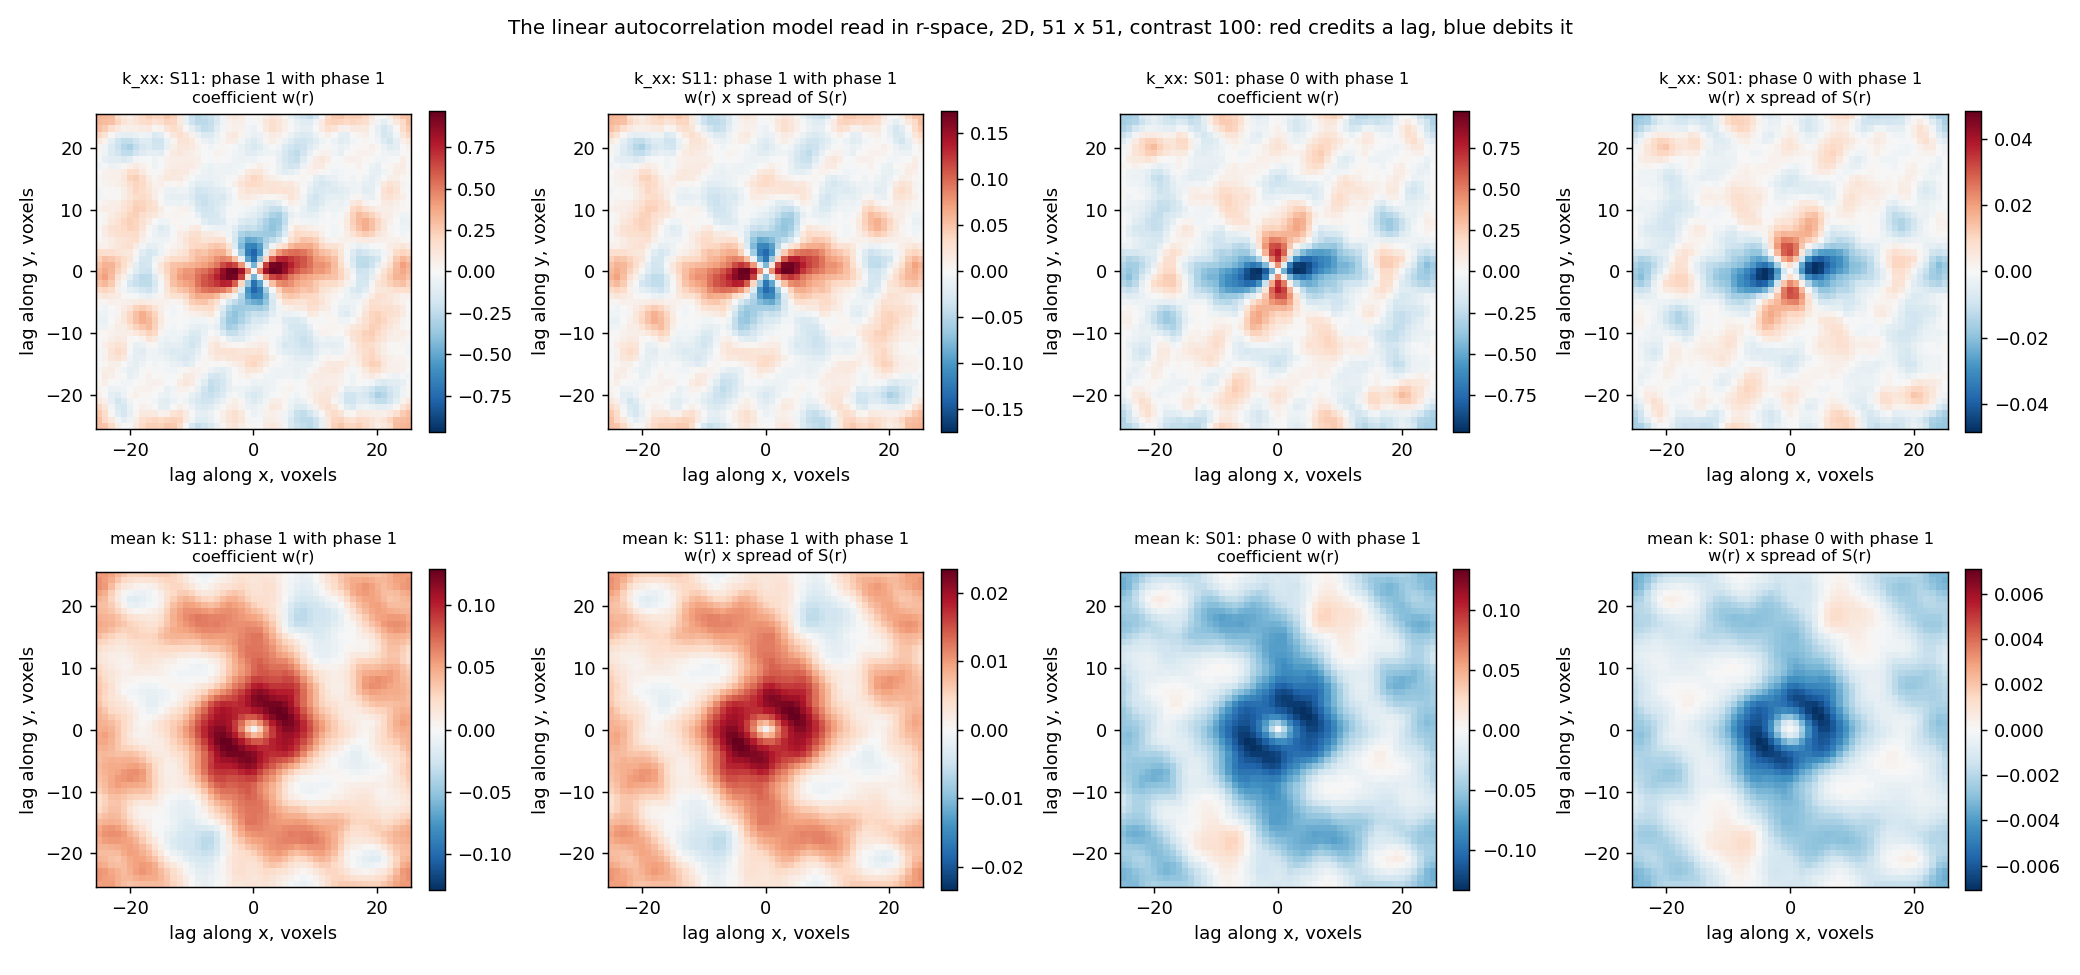

In [6]:
from IPython.display import Image, display
display(Image(filename="benchmarks/results/microstructure/map_2d51_n400_c100.png", width=700))

For k_xx (top row) the map credits phase 1 found again 2 to 8 voxels away along x, and debits it
across, along y: four lobes. For the direction-free mean (bottom row) it is a ring at the grain
size, about 5 voxels, in every direction. The right-hand panels of each pair weight the
coefficient by how much the statistic varies over the cells, which shows where the model's
predictions actually come from.

The three numbers give no such picture. Their regression says that a long correlation length
along x raises k_xx, which is the same knowledge in one number. The map shows it as a shape over
the lags, and for a structure not made from a few numbers it could show something that no chosen
number holds. On these cells it shows what the numbers already say.

## What to take from this notebook

- A microstructure on a grid is a field, and the overlap of the two-point statistics is the
  kernel of this program for it. It beats the phase fraction wherever the arrangement matters,
  and it matches the current MKS baseline.
- On these synthetic cells, three numbers measured on each cell (the phase fraction and the
  correlation lengths along the axes) predict the conductivity and the stiffness as well as the
  kernel, and in 2D better. The cells were made from four numbers, and the reference measures
  them. In 3D, where the grid is small, the kernel keeps a lead of 0.003 to 0.020.
- With a second scale, the product of two kernels learns faster on few cells. From 100 cells on,
  the numbers with the descriptor added do as well.
- The map over the lag vector is something the numbers do not give. On these cells it shows the
  same knowledge as the correlation lengths.
- On real micrographs (961 images of ultrahigh-carbon steel in the benchmark), the kernel is the
  best of the second-order descriptions, with an accuracy of 0.61 at 500 training images, and
  features of a convolutional network reach 0.87. A second-order statistic does not carry the
  shapes that name the classes.
- The rule of the earlier notebooks holds here too: before a field model of a microstructure is
  credited, give the few numbers a materials scientist would measure the same draws and a search
  of their own settings.

From the command line, the reference and the table:

```
python benchmarks/run_microstructure.py --stage shape
python benchmarks/run_microstructure.py --report
```

Where to read further in the manual: *A microstructure as the sample: the field on a voxel grid*
has the phase field, the co-field over the lag vector, all four tests of the gate and this
reference.